# Brain-only synthesis and histology section planning

Real anatomical labels → brain masking → bilateral contrast synthesis → appearance augmentation → representative section planes and corresponding 2D images.

Default data are public human anatomical segmentations. Matching left/right structures share intensity distributions. Parallel, slightly oblique coronal planes illustrate a plausible sectioning series; they are illustrative planning geometry, not a specimen-specific cutting protocol. Skull and background remain zero throughout.

Exact Pig127 reconstruction remains optional when its native MRI and saved transforms are available.

In [1]:
# Uncomment once in a fresh environment:
# %pip install numpy scipy nibabel matplotlib jupyter

from pathlib import Path
import json, sys, hashlib, subprocess, shutil, importlib.metadata
import numpy as np
import nibabel as nib
from nibabel.processing import resample_from_to
from scipy import ndimage as ndi
from scipy.spatial.transform import Rotation
import matplotlib.pyplot as plt

SEED = 2026
OUT = Path("pigtails_student_outputs")
OUT.mkdir(exist_ok=True)
print("Python:", sys.version)
for package in ["numpy", "scipy", "nibabel", "matplotlib"]:
    print(package, importlib.metadata.version(package))

Python: 3.11.18 (main, Oct 26 2026, 02:48:34) [GCC 13.3.0]
numpy 2.4.6
scipy 1.17.1
nibabel 5.5.0
matplotlib 3.11.2


## 1. Load the segmentation and inspect its IDs
A segmentation stores integer region IDs, not MRI intensities. Nibabel loads the image and its voxel-to-world affine. The public example is reoriented to RAS and sampled at 2 mm for memory efficiency.

For the public example, the brain mask explicitly selects standard anatomical brain labels, including ventricular spaces and excluding extracerebral CSF 24. Treat this as a analysis target convention. **No non-brain labels enter synthesis.**

For Pig127, set USE_LAB_DATA=True. The native MRI grid must stay unchanged because your saved planes use native indices. Supply reviewed labels and a binary mask on the same anatomy; resampling matches grids but does not register anatomy.

In [2]:
USE_LAB_DATA = False
WATER_PATH = Path("/replace/with/water.nii.gz")
LABEL_PATH = Path("/replace/with/reviewed_labels.nii.gz")
BRAIN_MASK_PATH = Path("/replace/with/reviewed_brain_mask.nii.gz")

def load_3d(path):
    image = nib.as_closest_canonical(nib.load(str(path)))
    if len(image.shape) != 3:
        raise ValueError(f"{path}: expected 3D, got {image.shape}. Select the intended volume explicitly.")
    if image.header.get_xyzt_units()[0] != "mm":
        raise ValueError("Confirm physical units and set a correct header before continuing.")
    return image

def integer_labels(image):
    a = image.get_fdata()
    if not np.isfinite(a).all() or not np.allclose(a, np.round(a)):
        raise ValueError("Labels must contain finite integers.")
    if a.min() < 0:
        raise ValueError("Use nonnegative label IDs.")
    return a.astype(np.int32)

if USE_LAB_DATA:
    source = nib.load(str(WATER_PATH))
    if len(source.shape) != 3 or source.header.get_xyzt_units()[0] != "mm":
        raise ValueError("Expected a 3D MRI in mm; preserve its native grid.")
    lab_source = load_3d(LABEL_PATH)
    mask_source = load_3d(BRAIN_MASK_PATH)
    integer_labels(lab_source)
    if not set(np.unique(integer_labels(mask_source))).issubset({0, 1}):
        raise ValueError("Brain mask must be binary.")
    labels = integer_labels(resample_from_to(lab_source, source, order=0))
    brain_mask = resample_from_to(mask_source, source, order=0).get_fdata() > 0
    water = source.get_fdata(dtype=np.float32)
    if not np.isfinite(water).all():
        raise ValueError("Water image has nonfinite values.")
    affine = source.affine.copy()
else:
    import urllib.request
    revision = "2a2aa3bbfccb83f8253a51ca8b329b9938a2646d"
    url = f"https://raw.githubusercontent.com/BBillot/SynthSeg/{revision}/data/training_label_maps/training_seg_01.nii.gz"
    example_path = OUT/"training_seg_01.nii.gz"
    if not example_path.exists():
        urllib.request.urlretrieve(url, example_path)
    raw = example_path.read_bytes()
    blob_sha = hashlib.sha1(b"blob " + str(len(raw)).encode() + b"\0" + raw).hexdigest()
    assert blob_sha == "ea35306c23022b2efc44ee5072547760744f8f38"
    native = nib.load(str(example_path))
    print("Loaded segmentation:", example_path)
    print("Original:", native.shape, nib.aff2axcodes(native.affine))
    from nibabel.processing import resample_to_output
    canonical = nib.as_closest_canonical(native)
    source = resample_to_output(canonical, voxel_sizes=(2, 2, 2), order=0)
    labels = integer_labels(source)
    affine = source.affine.copy()
    brain_ids = [2,3,4,5,7,8,10,11,12,13,14,15,16,17,18,26,28,
                 41,42,43,44,46,47,49,50,51,52,53,54,58,60]
    brain_mask = np.isin(labels, brain_ids)
    water = None  # no measured intensity image in the public segmentation example
assert brain_mask.any() and (~brain_mask).any()
assert 0 in labels, "Keep an explicit background label."
print("Shape:", labels.shape, "spacing:", nib.affines.voxel_sizes(affine))
print("Axes:", nib.aff2axcodes(affine), "label IDs:", np.unique(labels))

Loaded segmentation: pigtails_student_outputs/training_seg_01.nii.gz
Original: (256, 256, 256) ('L', 'I', 'A')
Shape: (129, 129, 129) spacing: [2. 2. 2.]
Axes: ('R', 'A', 'S') label IDs: [  0   2   3   4   5   7   8  10  11  12  13  14  15  16  17  18  24  25
  26  28  30  41  42  43  44  46  47  49  50  51  52  53  54  57  58  60
  62  72  85 136 137 163 164 502 506 507 508 509 511 512 514 515 516 530]


## 2. Skull-strip before all synthesis and augmentation
Skull stripping removes non-brain tissue using the brain mask. For an MRI, multiply intensities by the mask. For generation, also set every non-brain label to background 0. Retain the full image grid and affine.

This mask application is the skull-stripping step for the public segmented example. It does not run SynthStrip. If you need to predict a mask from a new pig MRI, obtain a reviewed PIGSKIN/pig-specific mask first. Never use the nonzero union of all segmentation labels as a brain mask.

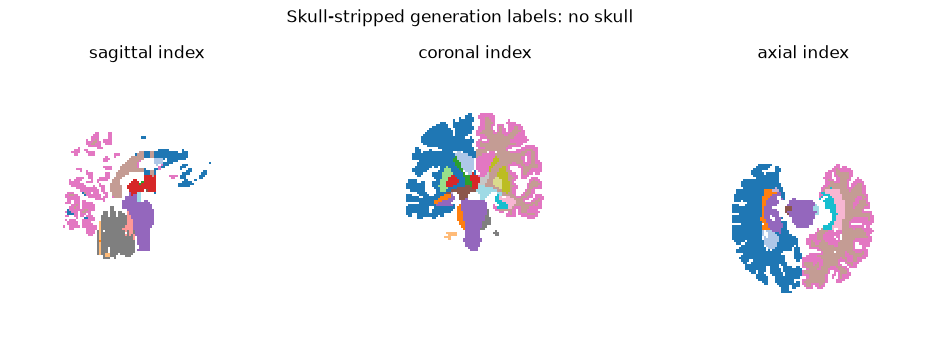

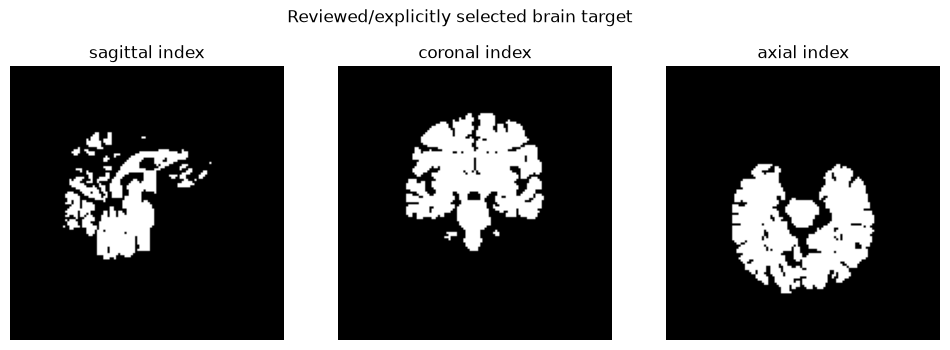

Brain label IDs: [ 0  2  3  4  5  7  8 10 11 12 13 14 15 16 17 18 26 28 41 42 43 44 46 47
 49 50 51 52 53 54 58 60]


In [3]:
def views(volume, title, mask=None):
    centre = np.array(volume.shape)//2
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for axis, (ax, name) in enumerate(zip(axes, ["sagittal index", "coronal index", "axial index"])):
        sl = np.take(volume, centre[axis], axis=axis).T
        is_labels = np.issubdtype(volume.dtype, np.integer) and volume.max() > 1
        if is_labels:
            ids = np.unique(volume)
            display_sl = np.searchsorted(ids, sl)
            ax.imshow(np.ma.masked_where(sl == 0, display_sl), origin="lower", cmap="tab20", vmin=1, vmax=len(ids)-1, interpolation="nearest")
            ax.set_facecolor("black")
        else:
            ax.imshow(sl, origin="lower", cmap="gray")
        if mask is not None:
            ms = np.take(mask, centre[axis], axis=axis).T
            if ms.any() and not ms.all():
                ax.contour(ms, levels=[.5], colors="lime", linewidths=.7)
        ax.set_title(name); ax.set_axis_off()
    fig.suptitle(title); plt.show()


# Strip BEFORE generating any synthetic intensities.
generation_labels = np.where(brain_mask, labels, 0).astype(np.int32)
stripped_water = np.where(brain_mask, water, 0).astype(np.float32) if USE_LAB_DATA else None
assert not generation_labels[~brain_mask].any()
if USE_LAB_DATA:
    views(stripped_water, "Skull-stripped MRI only", brain_mask)
views(generation_labels, "Skull-stripped generation labels: no skull")
views(brain_mask, "Reviewed/explicitly selected brain target")
print("Brain label IDs:", np.unique(generation_labels))


## 3. Optional tools: keep stripping before generation
SynthStrip predicts a mask; SynthSeg predicts anatomical labels; neither inference command generates synthetic MRI. On a new scan, first obtain and review the mask, then load it into BRAIN_MASK_PATH and rerun from section 1. For pig data prefer the validated lab PIGSKIN workflow. Do not treat human SynthSeg region predictions as pig ground truth.

The default lesson already has an anatomical mask and applies it above. Official references: [SynthStrip](https://surfer.nmr.mgh.harvard.edu/docs/synthstrip/), [SynthSeg](https://www.freesurfer.net/fswiki/SynthSeg), and [PIGSKIN](https://github.com/dadashkarimi/pigskin).

## 4. Generate several brain-only synthetic contrasts
Draw a mean and standard deviation for each brain region and sample its voxel intensities. Background is identically zero. These are Gaussian Gaussian label-to-image examples based on real anatomy, not quantitative water simulations and not actual TensorFlow SynthSeg generator outputs.

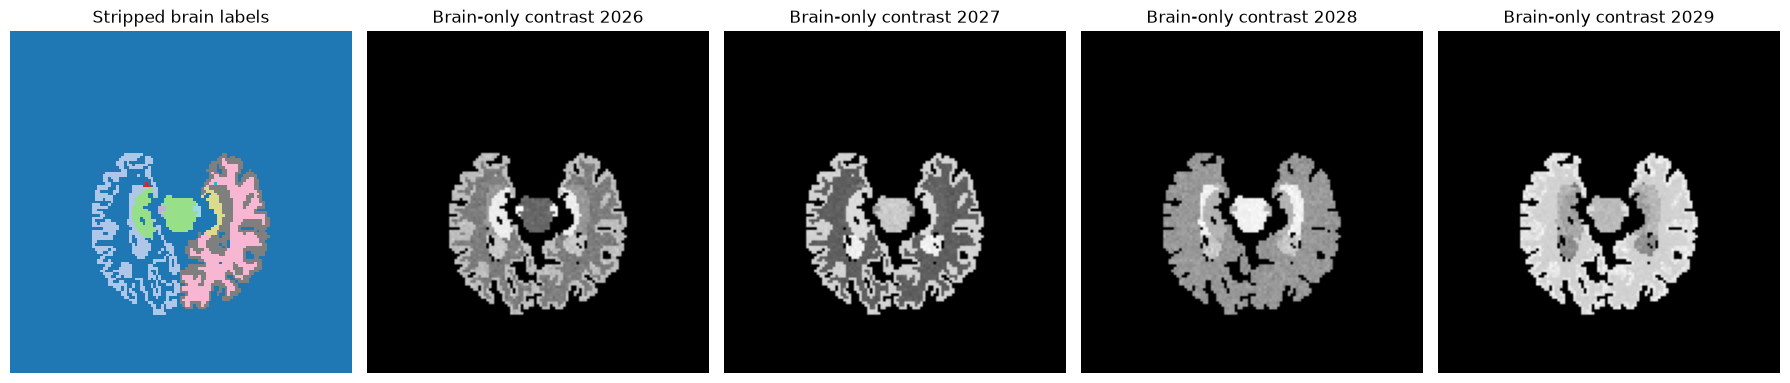

In [4]:
def synthesize(label_map, seed):
    rng = np.random.default_rng(seed)
    image = np.zeros(label_map.shape, np.float32)
    parameters = {}
    pairs = {41:2,42:3,43:4,44:5,46:7,47:8,49:10,50:11,51:12,52:13,53:17,54:18,58:26,60:28}
    shared = {}
    for k in np.unique(label_map):
        if k == 0:
            continue
        group = pairs.get(int(k), int(k))
        if group not in shared:
            shared[group] = (float(rng.uniform(.35, .9)), float(rng.uniform(.01, .035)))
        mean, std = shared[group]
        region = label_map == k
        image[region] = np.maximum(rng.normal(mean, std, region.sum()), 0)
        parameters[str(k)] = {"mean": mean, "std": std}
    return image, parameters

clean, contrast_params = synthesize(generation_labels, SEED)
assert np.count_nonzero(clean[~brain_mask]) == 0
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
z = generation_labels.shape[2]//2
axes[0].imshow(generation_labels[:,:,z].T, origin="lower", cmap="tab20", interpolation="nearest")
axes[0].set_title("Stripped brain labels")
for ax, seed in zip(axes[1:], [2026, 2027, 2028, 2029]):
    synthetic, _ = synthesize(generation_labels, seed)
    assert not synthetic[~brain_mask].any()
    ax.imshow(synthetic[:,:,z].T, origin="lower", cmap="gray")
    ax.set_title(f"Brain-only contrast {seed}")
for ax in axes: ax.set_axis_off()
fig.tight_layout()
fig.savefig(OUT/"real_brain_synthetic_examples.png", dpi=160, bbox_inches="tight")
plt.show()


## 5. Add bias, blur, and noise within the brain
Blur/noise can introduce values outside the support, so reapply the mask at the end. This maintains a strictly brain-only result. Labels are categorical and are never blurred.

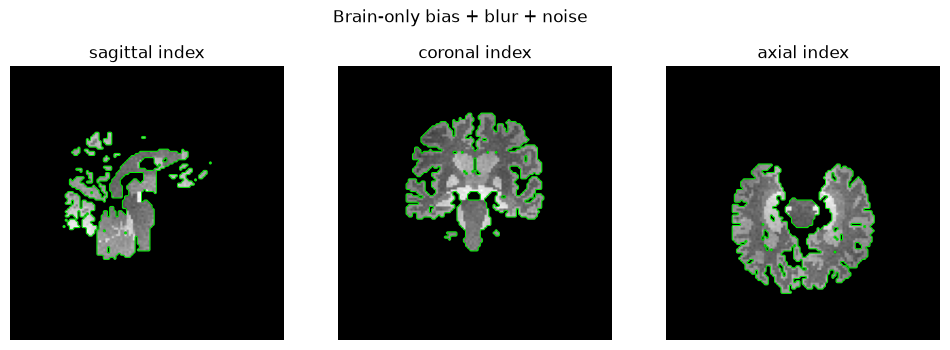

In [5]:
def appearance(image, seed, bias_strength=.25, blur_mm=.7, noise_std=.025):
    rng = np.random.default_rng(seed)
    field = ndi.gaussian_filter(rng.normal(size=image.shape).astype(np.float32), sigma=12)
    field /= max(float(field.std()), 1e-6)
    biased = image * np.exp(bias_strength*field)
    sigma = blur_mm / nib.affines.voxel_sizes(affine)
    blurred = ndi.gaussian_filter(biased, sigma=sigma)
    noisy = blurred + rng.normal(0, noise_std, image.shape)
    return np.where(brain_mask, np.clip(noisy, 0, None), 0).astype(np.float32)

aug_image = appearance(clean, SEED+2)
assert not aug_image[~brain_mask].any()
views(aug_image, "Brain-only bias + blur + noise", brain_mask)

## 6. Mild shared spatial augmentation
Image, labels, and mask share the same sampling coordinates. Image interpolation is linear; labels/masks use nearest neighbor. Reapply the transformed mask to prevent interpolated intensities leaking outside it.

For exact Pig127 histology locations, leave APPLY_SPATIAL_WARP=False. Warping anatomy without updating plane correspondence invalidates an anatomical match. The default enables ±3° rotation, 0.98–1.02 scaling, ±1 mm translation, and a smooth elastic displacement with 0.25 voxel standard deviation per axis. Two independent seeds produce two synthetic realizations.

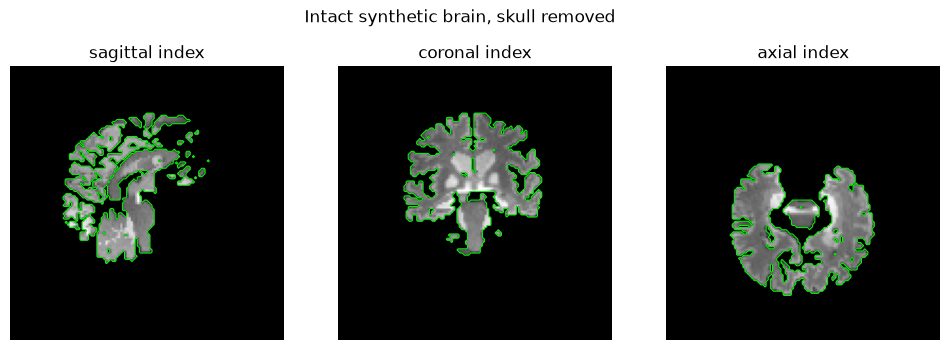

Rotation bounds: ±3 degrees; scale: 0.98–1.02; translation: ±1 mm
Elastic displacement: 0.25 voxel SD per axis (0.5 mm at default 2 mm spacing)
Realization 1: {'forward_world': [[1.0086956530972118, 0.007311898604807164, -0.04904878313834714, 0.07620840196484979], [-0.008834111086208095, 1.0093932098977414, -0.031200542614204414, -0.4042903810349844], [0.048797596968253705, 0.03159195335678485, 1.0082395105226718, -0.2227265984167046], [0.0, 0.0, 0.0, 1.0]], 'angles_deg': [1.7947060590805775, -2.7695284826532607, -0.5017810267913045], 'scale': 1.009913940673051, 'translation_mm': [0.035855271923714405, -0.44432503473539686, -0.16568949092577911], 'elastic_vox': 0.25, 'seed': 2029}
Realization 2: {'forward_world': [[0.9800187663633769, 0.046812714683100096, -0.027593725551060374, 0.8499423968280629], [-0.047720696141194785, 0.9798218073314693, -0.03258201049162722, 1.0754084273962905], [0.025991904616405742, 0.03387361793306723, 0.9805950363288202, -0.8619005708972893], [0.0, 0.0, 0.0, 

In [6]:
def sampling_coordinates(shape, affine, seed, elastic_vox=.25):
    rng = np.random.default_rng(seed)
    angles = rng.uniform(-3, 3, 3)
    rotation = Rotation.from_euler("xyz", angles, degrees=True).as_matrix()
    scale = float(rng.uniform(.98, 1.02))
    centre_world = nib.affines.apply_affine(affine, (np.array(shape)-1)/2)
    forward = np.eye(4)
    forward[:3, :3] = rotation * scale
    translation_mm = rng.uniform(-1, 1, 3)
    forward[:3, 3] = centre_world + translation_mm - forward[:3, :3] @ centre_world
    pull = np.linalg.inv(affine) @ np.linalg.inv(forward) @ affine
    ijk = np.indices(shape, dtype=np.float32).reshape(3, -1)
    coords = (pull[:3, :3] @ ijk + pull[:3, 3, None]).reshape((3,)+shape)
    for axis in range(3):
        d = ndi.gaussian_filter(rng.normal(size=shape).astype(np.float32), 10)
        d *= elastic_vox / max(float(d.std()), 1e-6)
        coords[axis] += d
    return coords, {"forward_world": forward.tolist(), "angles_deg": angles.tolist(),
                    "scale": scale, "translation_mm": translation_mm.tolist(),
                    "elastic_vox": elastic_vox, "seed": seed}


APPLY_SPATIAL_WARP = True
if APPLY_SPATIAL_WARP:
    coords, spatial_params = sampling_coordinates(generation_labels.shape, affine, SEED+3)
    warped_mask = ndi.map_coordinates(brain_mask.astype(np.uint8), coords, order=0,
                                     mode="constant", cval=0).astype(bool)
    warped_image = ndi.map_coordinates(aug_image, coords, order=1, mode="constant", cval=0)
    warped_labels = ndi.map_coordinates(generation_labels, coords, order=0, mode="constant", cval=0)
    warped_image = np.where(warped_mask, warped_image, 0).astype(np.float32)
    warped_labels = np.where(warped_mask, warped_labels, 0).astype(np.int32)
else:
    warped_image, warped_labels, warped_mask = aug_image, generation_labels, brain_mask
    spatial_params = {"enabled": False}
assert not warped_image[~warped_mask].any()
assert not warped_labels[~warped_mask].any()
views(warped_image, "Intact synthetic brain, skull removed", warped_mask)

# Independent second realization, with the same mild parameter ranges.
clean_second, contrast_second = synthesize(generation_labels, SEED+100)
appearance_second = appearance(clean_second, SEED+102)
coords_second, spatial_second = sampling_coordinates(generation_labels.shape, affine, SEED+103)
mask_second = ndi.map_coordinates(brain_mask.astype(np.uint8),coords_second,order=0,mode="constant",cval=0)>0
image_second = ndi.map_coordinates(appearance_second,coords_second,order=1,mode="constant",cval=0)
image_second = np.where(mask_second,image_second,0).astype(np.float32)
labels_second = ndi.map_coordinates(generation_labels,coords_second,order=0,mode="constant",cval=0)
labels_second = np.where(mask_second,labels_second,0).astype(np.int32)
assert not image_second[~mask_second].any()
print("Rotation bounds: ±3 degrees; scale: 0.98–1.02; translation: ±1 mm")
print("Elastic displacement: 0.25 voxel SD per axis (0.5 mm at default 2 mm spacing)")
print("Realization 1:", spatial_params)
print("Realization 2:", spatial_second)


## 7. Section geometry

The default series contains seven parallel, slightly oblique coronal planes through the central brain. This gives interpretable bilateral cross-sections representative of histology sectioning. Plane centres and normals are saved in physical coordinates. The optional exact Pig127 mode retains its original independent transform definitions.

In [7]:
def plane_coordinates(affine, centre_mm, normal, size=128, spacing_mm=1.0):
    normal = np.asarray(normal, float)
    if normal.shape != (3,) or not np.isfinite(normal).all() or np.linalg.norm(normal) == 0:
        raise ValueError("Normal must be a finite nonzero 3-vector.")
    n = normal / np.linalg.norm(normal)
    helper = np.eye(3)[np.argmin(np.abs(n))]
    u = np.cross(n, helper); u /= np.linalg.norm(u)
    v = np.cross(n, u)
    ticks = (np.arange(size)-(size-1)/2)*spacing_mm
    a, b = np.meshgrid(ticks, ticks, indexing="ij")
    world = np.asarray(centre_mm)[:, None, None] + u[:, None, None]*a + v[:, None, None]*b
    inverse = np.linalg.inv(affine)
    voxels = (inverse[:3, :3] @ world.reshape(3, -1) + inverse[:3, 3, None]).reshape(3, size, size)
    return voxels, {"centre_mm": np.asarray(centre_mm).tolist(), "normal": n.tolist(),
                    "u": u.tolist(), "v": v.tolist(), "spacing_mm": spacing_mm,
                    "size": size, "coordinate_system": "RAS"}


CLASSES = ["A3","A2","A1","P1","P2","P3","P4"]
SLICES_ZERO = {"A3":24,"A2":36,"A1":45,"P1":60,"P2":77,"P3":88,"P4":102}
NORMALS_LPS = {
    "A3":[.156400,.943284,.292839], "A2":[.096029,.966830,.236683],
    "A1":[.062908,.976839,.204518], "P1":[.074535,.924627,.373509],
    "P2":[-.007860,.953274,.302004], "P3":[.222757,.970514,-.092093],
    "P4":[.232638,.970819,.058227]}
EXACT_PIG127 = False
PIG127_TRANSFORM_DIR = Path("/replace/with/Pig127/transforms")
REFERENCE_GRID_PATH = None

def itk_matrix(path):
    text = path.read_text()
    records = [s.split(":",1)[1].strip() for s in text.splitlines() if s.startswith("Transform:")]
    if len(records) != 1 or records[0] not in (
            "MatrixOffsetTransformBase_double_3_3","AffineTransform_double_3_3"):
        raise ValueError("Expected one supported complete affine")
    p = np.fromstring(next(s.split(":",1)[1] for s in text.splitlines()
                          if s.startswith("Parameters:")), sep=" ")
    c = np.fromstring(next(s.split(":",1)[1] for s in text.splitlines()
                          if s.startswith("FixedParameters:")), sep=" ")
    if len(p) != 12 or len(c) != 3 or not np.isfinite(np.r_[p,c]).all():
        raise ValueError("Invalid affine")
    H = np.eye(4); H[:3,:3] = p[:9].reshape(3,3)
    H[:3,3] = p[9:] + c - H[:3,:3] @ c
    if abs(np.linalg.det(H[:3,:3])) < 1e-10:
        raise ValueError("Singular transform")
    return H

plane_samples, plane_metadata = {}, {}
if EXACT_PIG127:
    if not USE_LAB_DATA or APPLY_SPATIAL_WARP:
        raise ValueError("Exact Pig127 needs native lab data and no spatial warp")
    grid_image = nib.load(str(REFERENCE_GRID_PATH)) if REFERENCE_GRID_PATH else source
    if nib.aff2axcodes(source.affine) != ("L","P","S") or grid_image.shape[1] != 176:
        raise ValueError("Pig127 native geometry does not match the attached reference")
    F = np.diag([-1.,-1.,1.,1.])
    G_source, G_grid = F @ affine, F @ grid_image.affine
    I,K = np.meshgrid(np.arange(grid_image.shape[0]),np.arange(grid_image.shape[2]),indexing="ij")
    for name in CLASSES:
        T = itk_matrix(PIG127_TRANSFORM_DIR/f"PRO_127_6mo_{name}_xfm.txt")
        points = np.stack([I,np.full_like(I,SLICES_ZERO[name]),K],axis=0).reshape(3,-1)
        pull = np.linalg.inv(G_source) @ T @ G_grid
        pc = (pull[:3,:3] @ points + pull[:3,3,None]).reshape((3,)+I.shape)
        plane_samples[name] = pc
        plane_metadata[name] = {"mode":"exact_native_Pig127","j":SLICES_ZERO[name],
                                "output_to_source_LPS":T.tolist()}
else:
    # Match orientations only. Positions have no claimed Pig127 correspondence.
    brain_points = np.column_stack(np.nonzero(warped_mask))
    centre = nib.affines.apply_affine(affine, brain_points.mean(axis=0))
    points_world = nib.affines.apply_affine(affine, brain_points)
    lo,hi = np.percentile(points_world[:,1], [25,75])
    positions = np.linspace(hi,lo,len(CLASSES))
    for name, position in zip(CLASSES,positions):
        normal_ras = np.array([0., 1., .12])  # parallel slightly oblique coronal sectioning
        point = centre.copy(); point[1] = position
        pc, meta = plane_coordinates(affine,point,normal_ras,size=160,spacing_mm=1.)
        meta.update(mode="representative_parallel_histology_sections",
                    section_order=CLASSES.index(name)+1)
        plane_samples[name],plane_metadata[name] = pc,meta
print("Plane positions:", "exact Pig127" if EXACT_PIG127 else "illustrative human; Pig127 orientations only")


Plane positions: illustrative human; Pig127 orientations only


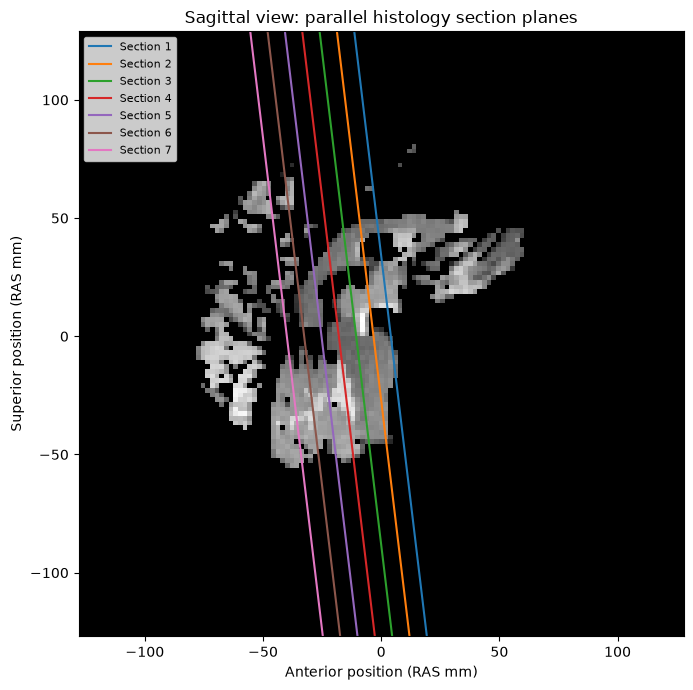

In [8]:
# Sagittal planning view with the section-plane intersections.
if not EXACT_PIG127:
    i = int(np.round(np.column_stack(np.nonzero(warped_mask))[:,0].mean()))
    fig, ax = plt.subplots(figsize=(10,7))
    y = affine[1,3] + affine[1,1]*np.arange(warped_image.shape[1])
    z = affine[2,3] + affine[2,2]*np.arange(warped_image.shape[2])
    ax.imshow(warped_image[i,:,:].T,origin="lower",cmap="gray",
              extent=[y[0],y[-1],z[0],z[-1]],aspect="equal")
    x = nib.affines.apply_affine(affine,[i,0,0])[0]
    for number,name in enumerate(CLASSES,1):
        meta = plane_metadata[name]
        p = np.array(meta["centre_mm"]); normal = np.array(meta["normal"])
        yy = p[1] - (normal[0]*(x-p[0])+normal[2]*(z-p[2]))/normal[1]
        ax.plot(yy,z,lw=1.5,label=f"Section {number}")
    ax.set_xlabel("Anterior position (RAS mm)")
    ax.set_ylabel("Superior position (RAS mm)")
    ax.set_title("Sagittal view: parallel histology section planes")
    ax.legend(loc="upper left",fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT/"histology_plane_layout.png",dpi=160)
    plt.show()


## 8. Two rows of synthetic sections
Each section samples the intact brain-only synthetic image. The same coordinates sample its brain mask and label map. Apply the sampled mask again so every outside-brain pixel remains zero. No half-space is removed and no skull is generated.

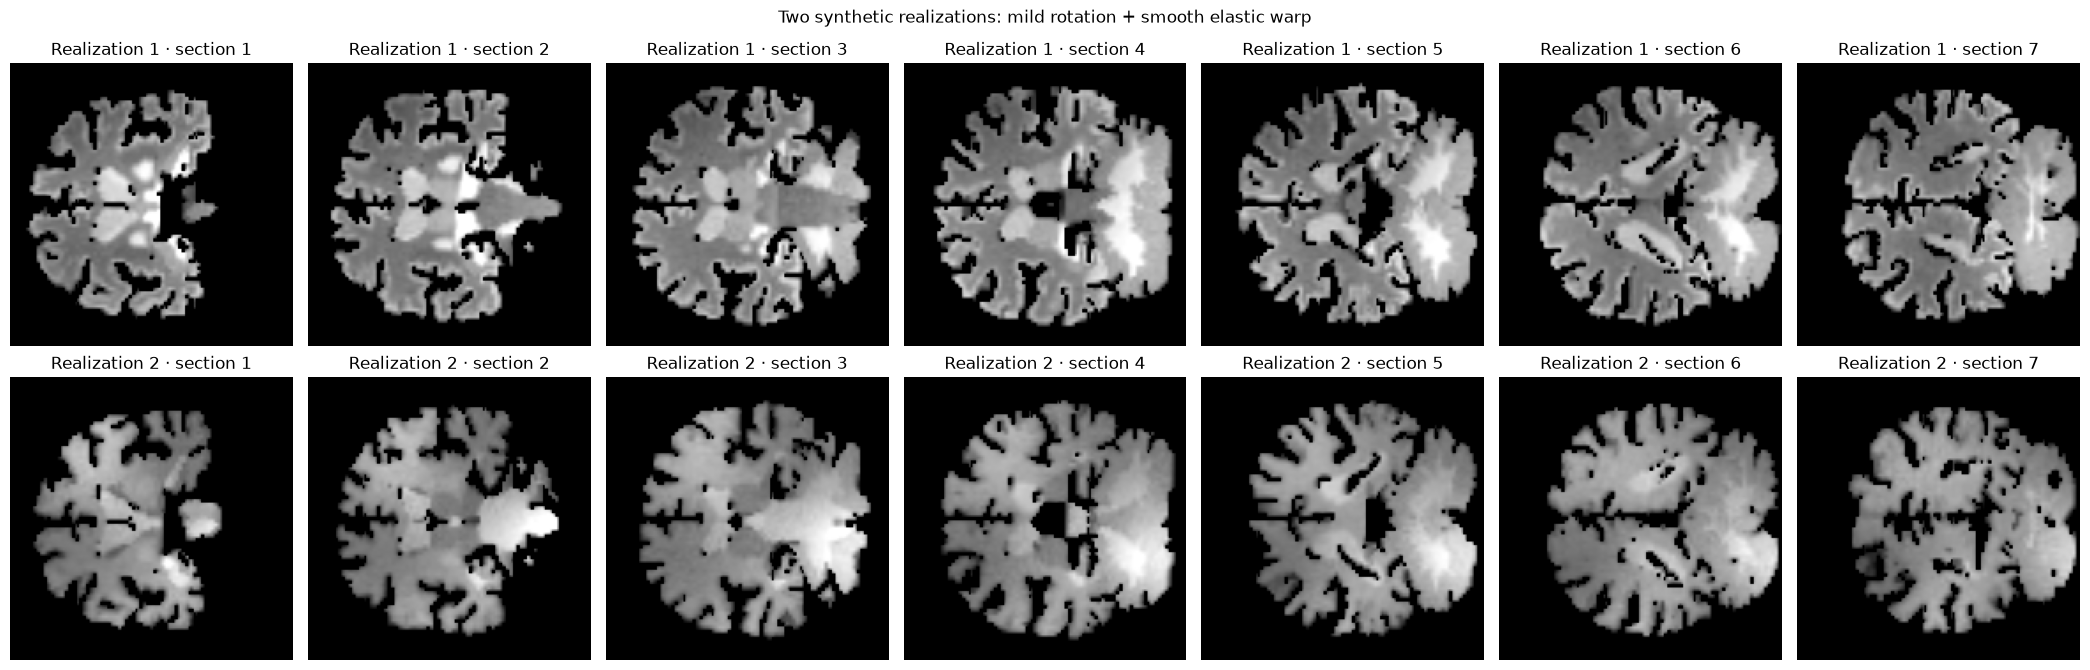

In [9]:
plane_exports = {}
fig, axes = plt.subplots(2,7,figsize=(21,7))
realizations = [(warped_image,warped_labels,warped_mask),(image_second,labels_second,mask_second)]
for row,(volume,regions,support) in enumerate(realizations):
    for col,name in enumerate(CLASSES):
        pc = plane_samples[name]  # identical physical planes for both realizations
        section_mask = ndi.map_coordinates(support.astype(np.uint8),pc,order=0,mode="constant",cval=0)>0
        section = ndi.map_coordinates(volume,pc,order=1,mode="constant",cval=0)
        section = np.where(section_mask,section,0).astype(np.float32)
        section_labels = ndi.map_coordinates(regions,pc,order=0,mode="constant",cval=0)
        section_labels = np.where(section_mask,section_labels,0).astype(np.int32)
        assert not section[~section_mask].any()
        axes[row,col].imshow(section.T,origin="lower",cmap="gray",vmin=0,vmax=1.)
        axes[row,col].set_title(f"Realization {row+1} · section {col+1}")
        axes[row,col].set_axis_off()
        plane_exports[f"r{row+1}_{name}"] = (section,section_labels,section_mask,plane_metadata[name])
fig.suptitle("Two synthetic realizations: mild rotation + smooth elastic warp")
fig.tight_layout()
fig.savefig(OUT/"real_brain_plane_examples.png",dpi=160,bbox_inches="tight")
plt.show()


## 9. Export brain-only images and 2D sections
Keep the full brain intact. All outside-brain values are zero, including after interpolation. Each 2D section is stored with its labels, mask, and geometry metadata. Split original subjects before augmentation to prevent leakage.

In [10]:
def save_volume(name,data,dtype):
    im = nib.Nifti1Image(np.asarray(data,dtype=dtype),affine)
    im.header.set_xyzt_units("mm")
    nib.save(im,OUT/name)
save_volume("synthetic_brain_only.nii.gz",warped_image,np.float32)
save_volume("brain_labels_only.nii.gz",warped_labels,np.int32)
save_volume("brain_mask.nii.gz",warped_mask,np.uint8)
for name,(im,lab,mask,meta) in plane_exports.items():
    np.savez_compressed(OUT/f"plane_{name}.npz",image=im,labels=lab,mask=mask)
    (OUT/f"plane_{name}.json").write_text(json.dumps(meta,indent=2))
assert np.count_nonzero(warped_image[~warped_mask]) == 0
assert np.count_nonzero(warped_labels[~warped_mask]) == 0
manifest = {
    "seed":SEED,"skull_stripping":"reviewed/explicit anatomical brain mask applied before synthesis",
    "skull_in_synthetic":False,"background_value":0,"resection":False,
    "source":"lab" if USE_LAB_DATA else "real public SynthSeg anatomical segmentation",
    "planes":"exact Pig127" if EXACT_PIG127 else "Pig127 orientations; illustrative human locations",
    "spatial":spatial_params,"spatial_second":spatial_second,"contrast_second":contrast_second,"contrast":contrast_params,"affine":affine.tolist(),
    "versions":{p:importlib.metadata.version(p) for p in ["numpy","scipy","nibabel","matplotlib"]}}
(OUT/"manifest.json").write_text(json.dumps(manifest,indent=2))
print("PASS: no skull/background intensity in any synthetic volume or plane")
print("Saved",len(plane_exports),"brain-only 2D sections to",OUT.resolve())

save_volume("synthetic_brain_only_second.nii.gz",image_second,np.float32)
save_volume("brain_labels_only_second.nii.gz",labels_second,np.int32)
save_volume("brain_mask_second.nii.gz",mask_second,np.uint8)


PASS: no skull/background intensity in any synthetic volume or plane
Saved 14 brain-only 2D sections to /home/runner/work/pigskin/pigskin/pigtails_student_outputs


## 10. Optional actual SynthSeg generation
The displayed default examples use the transparent Gaussian generator above. To use the actual TensorFlow generator, install the official [SynthSeg](https://github.com/BBillot/SynthSeg) environment separately. Pass **generation_labels after stripping**, disable flipping for arbitrary pig IDs, and reapply the generated foreground mask. This section is optional and not executed by default.

With cropped/deformed output, preserve the returned image/label correspondence but do not claim native histology-plane correspondence. Exact Pig127 planes require unchanged anatomy/grid.

In [11]:
RUN_SYNTHSEG_GENERATOR = False
if RUN_SYNTHSEG_GENERATOR:
    import tensorflow as tf
    from SynthSeg.brain_generator import BrainGenerator
    np.random.seed(SEED); tf.random.set_seed(SEED)
    path = OUT/"stripped_generator_input.nii.gz"
    im = nib.Nifti1Image(generation_labels,affine); im.header.set_xyzt_units("mm")
    nib.save(im,path)
    generator = BrainGenerator(labels_dir=str(path),generation_labels=np.unique(generation_labels),
        output_labels=np.unique(generation_labels),batchsize=1,n_channels=1,
        output_shape=[96,96,96],target_res=1.,flipping=False,
        scaling_bounds=.1,rotation_bounds=10,nonlin_std=2.,randomise_res=True,bias_field_std=.3)
    actual_image,actual_labels = generator.generate_brain()
    actual_mask = actual_labels != 0
    actual_image = np.where(actual_mask,actual_image,0).astype(np.float32)
    assert not actual_image[~actual_mask].any()
    views(actual_image,"Actual SynthSeg result: brain only",actual_mask)
